In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [15]:
df=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Kc_house_data_preprocessed.csv")

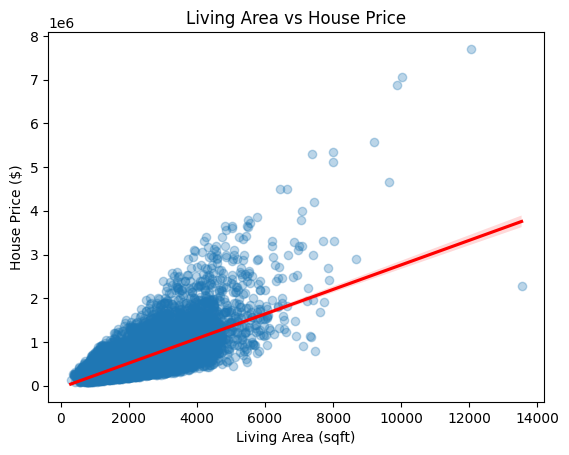

In [16]:
sns.regplot(
    data=df,
    x="sqft_living",
    y="price",
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)

plt.title("Living Area vs House Price")
plt.xlabel("Living Area (sqft)")
plt.ylabel("House Price ($)")
plt.show()

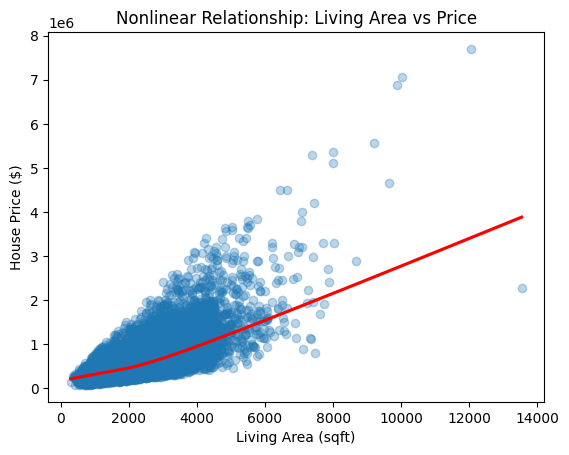

In [17]:
sns.regplot(
    data=df,
    x="sqft_living",
    y="price",
    lowess=True,
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)
plt.title("Nonlinear Relationship: Living Area vs Price")
plt.xlabel("Living Area (sqft)")
plt.ylabel("House Price ($)")
plt.show()

In [18]:
df["price_per_sqft_living"] = (
    df["price"] / df["sqft_living"].replace(0, np.nan)
)
plt.figure(figsize=(10, 6))

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

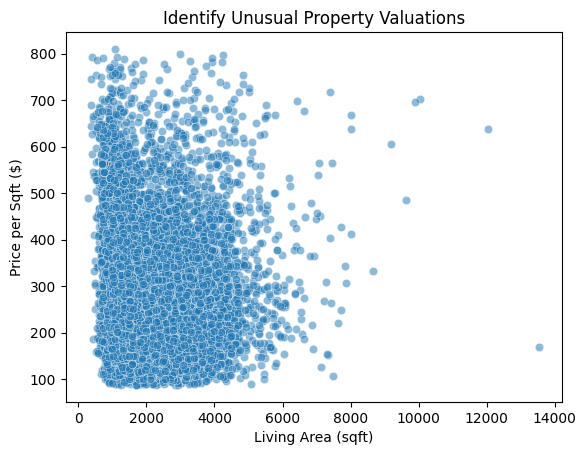

In [19]:
sns.scatterplot(
    data=df,
    x="sqft_living",
    y="price_per_sqft_living",
    alpha=0.5
)
plt.title("Identify Unusual Property Valuations")
plt.xlabel("Living Area (sqft)")
plt.ylabel("Price per Sqft ($)")
plt.show()

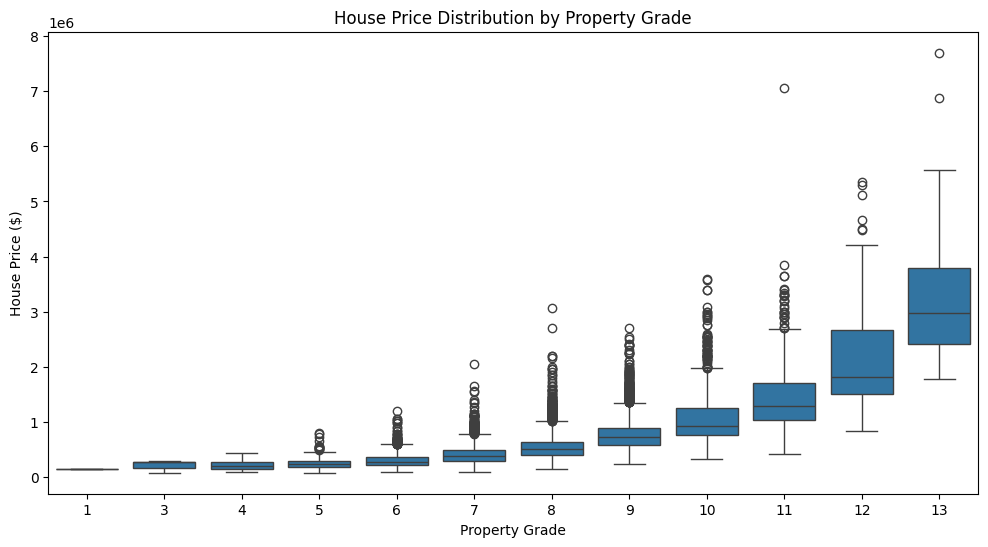

In [20]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="grade", y="price")
plt.title("House Price Distribution by Property Grade")
plt.xlabel("Property Grade")
plt.ylabel("House Price ($)")
plt.show()

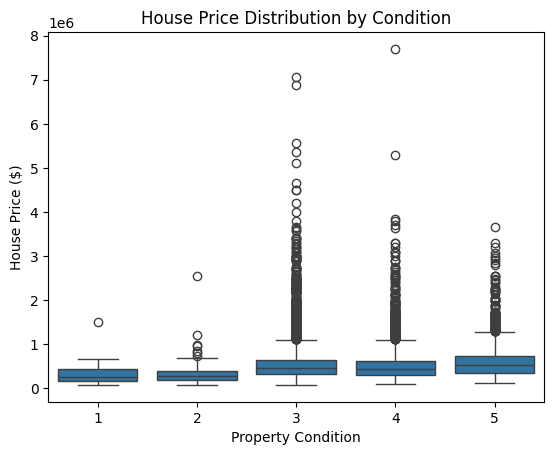

In [21]:

sns.boxplot(data=df, x="condition", y="price")
plt.title("House Price Distribution by Condition")
plt.xlabel("Property Condition")
plt.ylabel("House Price ($)")
plt.show()

In [22]:
print("Median Price by Grade:")
print(df.groupby("grade")["price"].median())
print("\nMedian Price by Condition:")
print(df.groupby("condition")["price"].median())

Median Price by Grade:
grade
1      142000.0
3      262000.0
4      205000.0
5      228700.0
6      275276.5
7      375000.0
8      510000.0
9      720000.0
10     914327.0
11    1284000.0
12    1817500.0
13    2983000.0
Name: price, dtype: float64

Median Price by Condition:
condition
1    262500.0
2    279000.0
3    450000.0
4    440000.0
5    526000.0
Name: price, dtype: float64


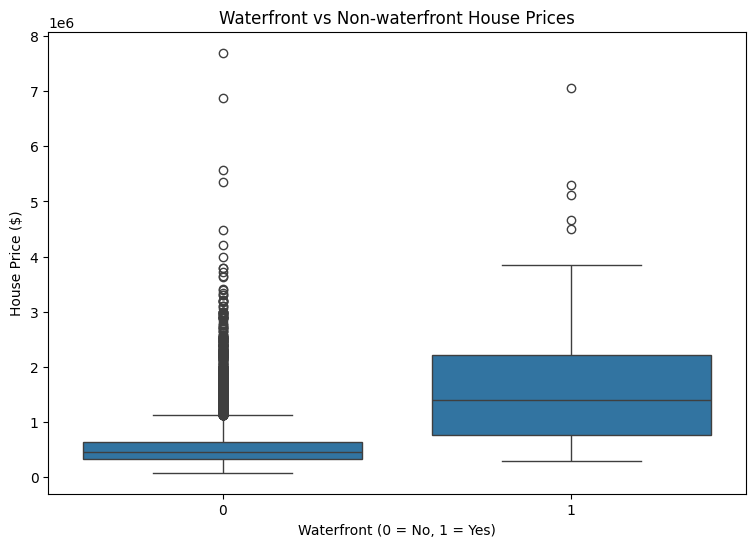

In [23]:
plt.figure(figsize=(9, 6))
sns.boxplot(data=df, x="waterfront", y="price")
plt.title("Waterfront vs Non-waterfront House Prices")
plt.xlabel("Waterfront (0 = No, 1 = Yes)")
plt.ylabel("House Price ($)")
plt.show()

In [24]:
waterfront_prices = df.groupby("waterfront")["price"].agg(
    ["count", "mean", "median"]
)
print(waterfront_prices)
median_no = df.loc[df["waterfront"] == 0, "price"].median()
median_yes = df.loc[df["waterfront"] == 1, "price"].median()
difference = median_yes - median_no
premium = (difference / median_no) * 100
print("\nMedian Price Difference: $", round(difference, 2))
print("Observed Median Price Difference (%):", round(premium, 2))

            count          mean     median
waterfront                                
0           21450  5.315636e+05   450000.0
1             163  1.661876e+06  1400000.0

Median Price Difference: $ 950000.0
Observed Median Price Difference (%): 211.11


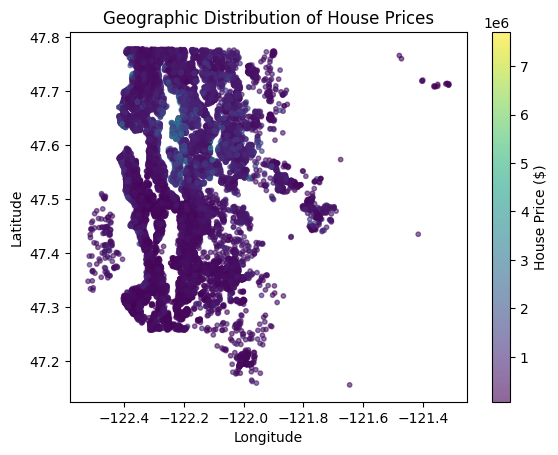

In [25]:
scatter = plt.scatter(
    df["long"],
    df["lat"],
    c=df["price"],
    cmap="viridis",
    s=10,
    alpha=0.6
)
plt.colorbar(scatter, label="House Price ($)")
plt.title("Geographic Distribution of House Prices")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

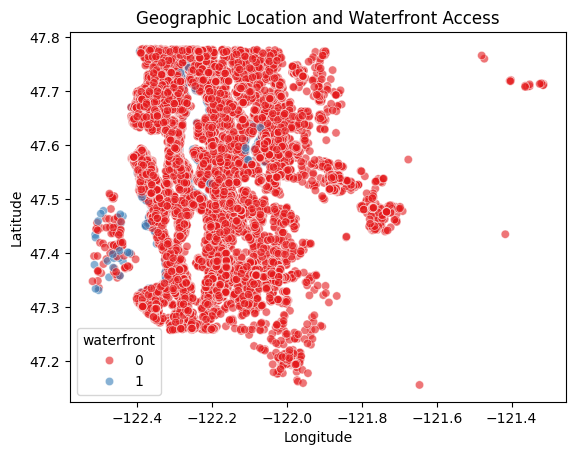

In [26]:
sns.scatterplot(
    data=df,
    x="long",
    y="lat",
    hue="waterfront",
    palette="Set1",
    alpha=0.6
)
plt.title("Geographic Location and Waterfront Access")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

In [27]:
if "property_age" not in df.columns:
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df["sale_year"] = df["date"].dt.year
    df["property_age"] = df["sale_year"] - df["yr_built"]

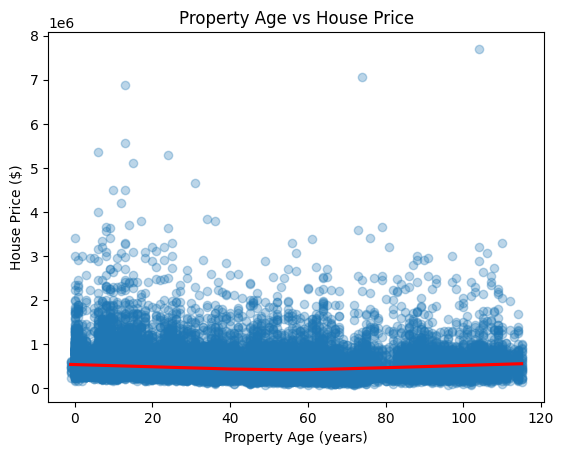

In [28]:
sns.regplot(
    data=df,
    x="property_age",
    y="price",
    lowess=True,
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)
plt.title("Property Age vs House Price")
plt.xlabel("Property Age (years)")
plt.ylabel("House Price ($)")
plt.show()

In [29]:
if "is_renovated" not in df.columns:
    df["is_renovated"] = (
        df["yr_renovated"].fillna(0) > 0
    ).astype(int)

renovation_prices = df.groupby("is_renovated")["price"].mean()

In [30]:
renovation_prices.index = [
    "Non-renovated" if i == 0 else "Renovated"
    for i in renovation_prices.index
]

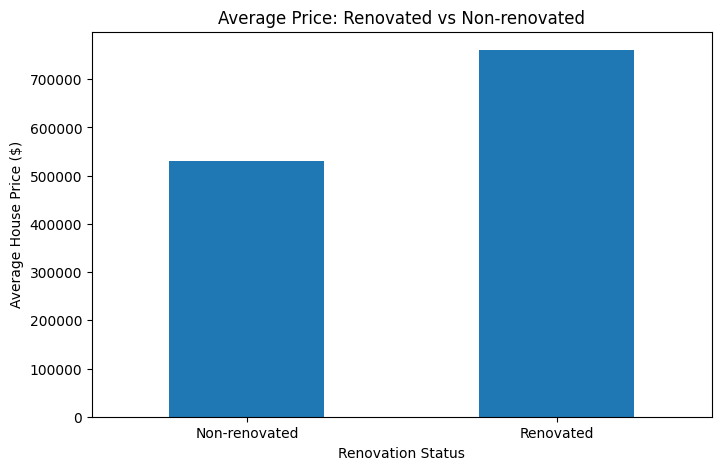

Non-renovated    530360.818155
Renovated        760379.029540
Name: price, dtype: float64


In [31]:
renovation_prices.plot(kind="bar", figsize=(8, 5))
plt.title("Average Price: Renovated vs Non-renovated")
plt.xlabel("Renovation Status")
plt.ylabel("Average House Price ($)")
plt.xticks(rotation=0)
plt.show()
print(renovation_prices)

In [32]:
df["price_per_sqft_living"] = (
    df["price"] / df["sqft_living"].replace(0, np.nan)
)

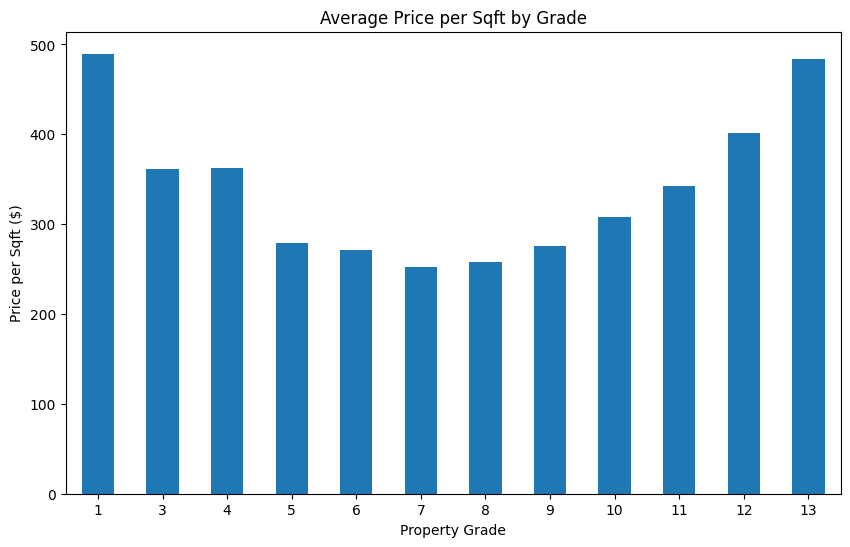

In [33]:
grade_price = df.groupby("grade")["price_per_sqft_living"].mean()
grade_price.plot(kind="bar", figsize=(10, 6))
plt.title("Average Price per Sqft by Grade")
plt.xlabel("Property Grade")
plt.ylabel("Price per Sqft ($)")
plt.xticks(rotation=0)
plt.show()

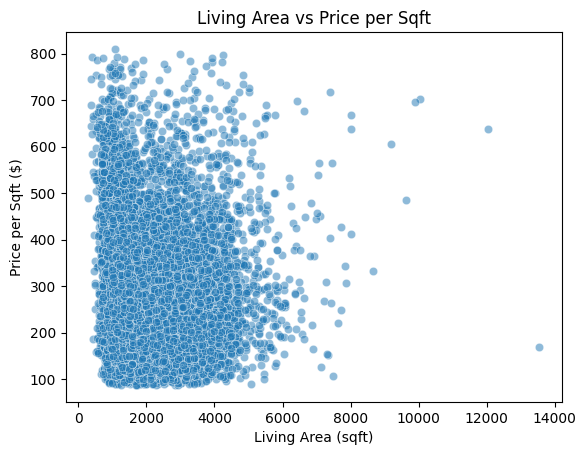

In [34]:
sns.scatterplot(
    data=df,
    x="sqft_living",
    y="price_per_sqft_living",
    alpha=0.5
)
plt.title("Living Area vs Price per Sqft")
plt.xlabel("Living Area (sqft)")
plt.ylabel("Price per Sqft ($)")
plt.show()

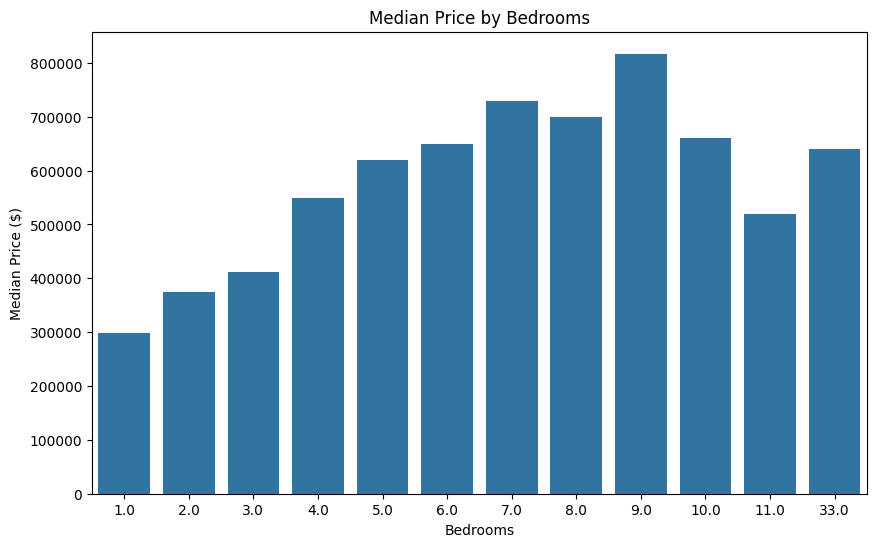

In [35]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=df,
    x="bedrooms",
    y="price",
    estimator=np.median,
    errorbar=None
)
plt.title("Median Price by Bedrooms")
plt.xlabel("Bedrooms")
plt.ylabel("Median Price ($)")
plt.show()

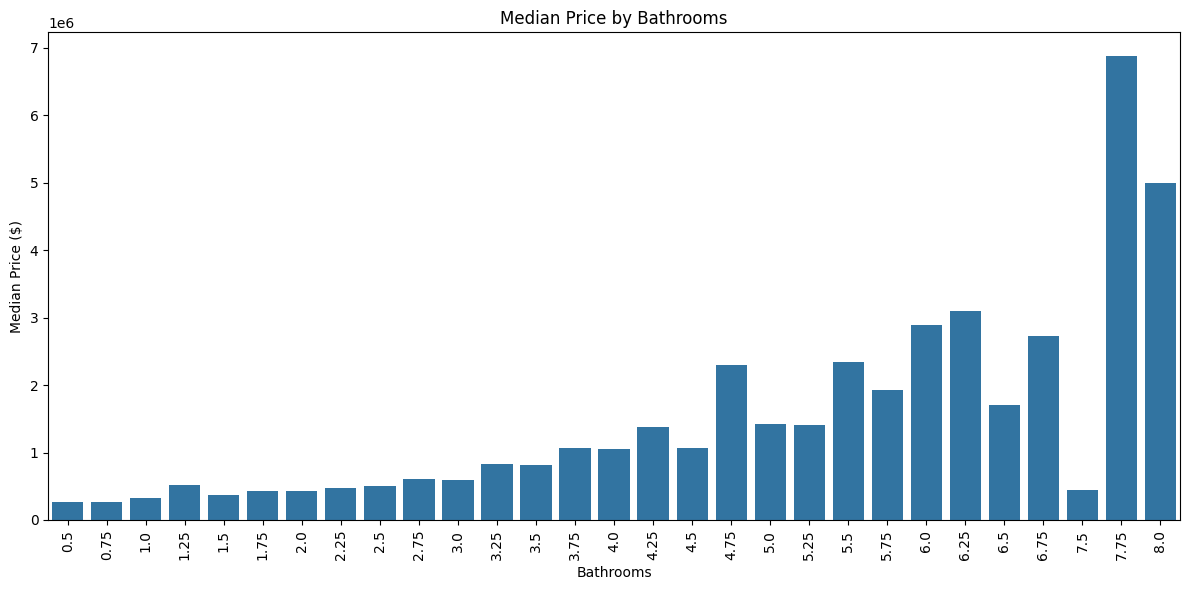

In [36]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df,
    x="bathrooms",
    y="price",
    estimator=np.median,
    errorbar=None
)
plt.title("Median Price by Bathrooms")
plt.xlabel("Bathrooms")
plt.ylabel("Median Price ($)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [37]:
threshold = df["price"].quantile(0.90)
high_value = df[df["price"] >= threshold].copy()
print("Top 10% House Price Threshold: $", round(threshold, 2))
print("Number of High-Value Properties:", len(high_value))

Top 10% House Price Threshold: $ 887000.0
Number of High-Value Properties: 2163


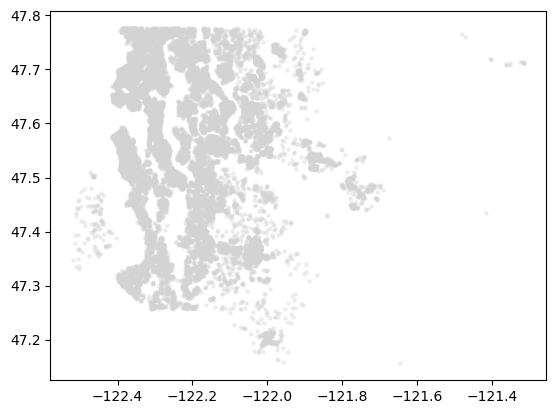

In [38]:
plt.scatter(
    df["long"], df["lat"],
    color="lightgray", s=5, alpha=0.3,
    label="Other Properties"
)

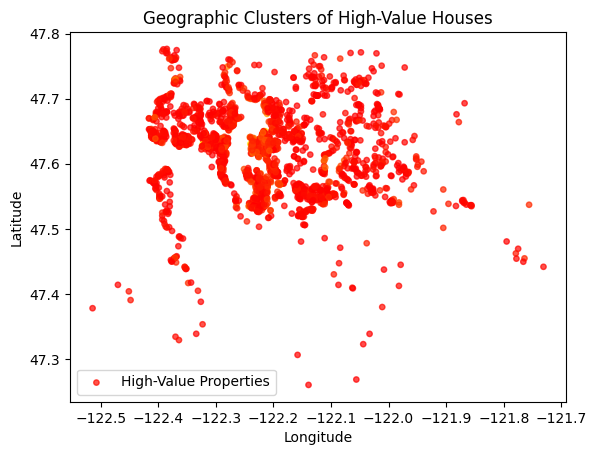

In [39]:
plt.scatter(
    high_value["long"], high_value["lat"],
    c=high_value["price"], cmap="autumn",
    s=15, alpha=0.7,
    label="High-Value Properties"
)
plt.title("Geographic Clusters of High-Value Houses")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()

In [40]:
print("REAL-ESTATE INVESTMENT SUMMARY")
print("\n1. Overall Price Statistics")
print(df["price"].describe())
print("\n2. Median Price by Grade")
print(df.groupby("grade")["price"].median())
print("\n3. Median Price by Condition")
print(df.groupby("condition")["price"].median())
print("\n4. Median Price by Waterfront")
print(df.groupby("waterfront")["price"].median())
print("\n5. Average Price by Renovation Status")
print(df.groupby("is_renovated")["price"].mean())
print("\n6. Top Geographic Areas (Zipcodes by Median Price)")
top_zipcodes = df.groupby("zipcode")["price"].median().sort_values(ascending=False).head(10)
print(top_zipcodes)

REAL-ESTATE INVESTMENT SUMMARY

1. Overall Price Statistics
count    2.161300e+04
mean     5.400881e+05
std      3.671272e+05
min      7.500000e+04
25%      3.219500e+05
50%      4.500000e+05
75%      6.450000e+05
max      7.700000e+06
Name: price, dtype: float64

2. Median Price by Grade
grade
1      142000.0
3      262000.0
4      205000.0
5      228700.0
6      275276.5
7      375000.0
8      510000.0
9      720000.0
10     914327.0
11    1284000.0
12    1817500.0
13    2983000.0
Name: price, dtype: float64

3. Median Price by Condition
condition
1    262500.0
2    279000.0
3    450000.0
4    440000.0
5    526000.0
Name: price, dtype: float64

4. Median Price by Waterfront
waterfront
0     450000.0
1    1400000.0
Name: price, dtype: float64

5. Average Price by Renovation Status
is_renovated
0    530360.818155
1    760379.029540
Name: price, dtype: float64

6. Top Geographic Areas (Zipcodes by Median Price)
zipcode
98039    1892500.0
98004    1150000.0
98040     993750.0
98112     9

In [41]:
columns = [
    "price", "sqft_living", "sqft_lot",
    "bedrooms", "bathrooms", "grade",
    "condition", "waterfront", "property_age"
]
available = [col for col in columns if col in df.columns]
correlation = df[available].corr(numeric_only=True)

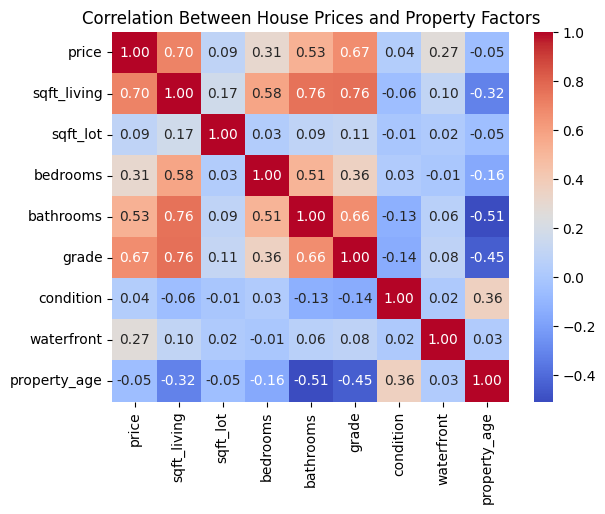


Correlation with Price:
price           1.000000
sqft_living     0.702035
grade           0.667434
bathrooms       0.525714
bedrooms        0.308868
waterfront      0.266369
sqft_lot        0.089661
condition       0.036362
property_age   -0.053951
Name: price, dtype: float64


In [42]:
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between House Prices and Property Factors")
plt.show()
print("\nCorrelation with Price:")
print(correlation["price"].sort_values(ascending=False))